In [1]:
import numpy as np
import numba as nb
import scipy.stats as stats
import torch
import matplotlib.pyplot as plt
import pickle
import yaml

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.utils.user_input_checks import process_simulator
from sbi.inference.potentials import ratio_estimator_based_potential
from sbi.inference.posteriors import MCMCPosterior

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from functools import partial
import simulator as sim

In [3]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

In [4]:
with open("/home/dingeldein/Desktop/fret_sbi/fret_sbi_double_well_benchmarkt/conf/simulator/high_photon_rate.yaml", 'r') as f:
    config = yaml.safe_load(f)

sim_cfg = config['simulator']
prior_cfg = config['prior']

In [5]:
prior = utils.BoxUniform(
    low=torch.tensor([prior_cfg['logD_lims'][0], prior_cfg['dG_lims'][0]]),
    high=torch.tensor([prior_cfg['logD_lims'][1], prior_cfg['dG_lims'][1]]),
    device="cuda"
)

In [6]:
fret_simulator = partial(
    sim.fret_simulator,
    T=sim_cfg['total_time'],
    R0=sim_cfg['R0'],
    photon_rate=sim_cfg['photon_rate'],
    deltax=sim_cfg['deltax']
)

fret_simulator = process_simulator(fret_simulator, is_numpy_simulator=True, prior=prior)

In [36]:
true_params = torch.tensor([[0.0, 7] for _ in range(5)])

In [37]:
observation = fret_simulator(true_params)

Text(0.5, 0, 'Time')

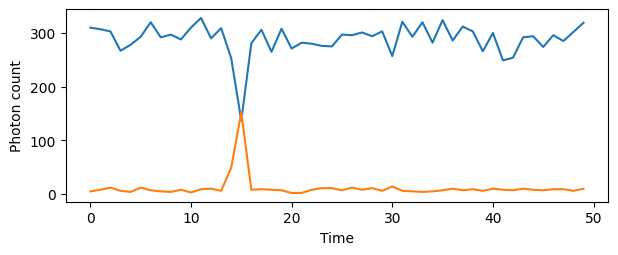

In [38]:
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[0, :,0].numpy(), n_bins=50), label="Donor")
plt.plot(bin_along_time(observation[0, :,1].numpy(), n_bins=50), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")


In [39]:
with open("/home/dingeldein/Desktop/fret_sbi/fret_sbi_double_well_benchmarkt/outputs/ratio_estimator/2026-02-20/18-50-43/ratio_estimator.pkl", "rb") as f:
    ratio_estimator = pickle.load(f)

In [40]:
potential, tf = ratio_estimator_based_potential(ratio_estimator, prior, observation.cuda())
posterior = MCMCPosterior(
    potential,
    proposal=prior,
    theta_transform=tf,
    num_chains=2,
    thin=2,
    method="slice_np_vectorized",
)

In [41]:
samples = posterior.sample(
    (3000,), 
    x=observation.cuda(),
    init_strategy_parameters={'num_candidate_samples': 100},  # Reduce from default to avoid 32-bit index overflow
).cpu()

Running vectorized MCMC with 2 chains: 100%|██████████| 6900/6900 [03:02<00:00, 37.85it/s]


/tmp/ipykernel_1041645/1014230753.py:1: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


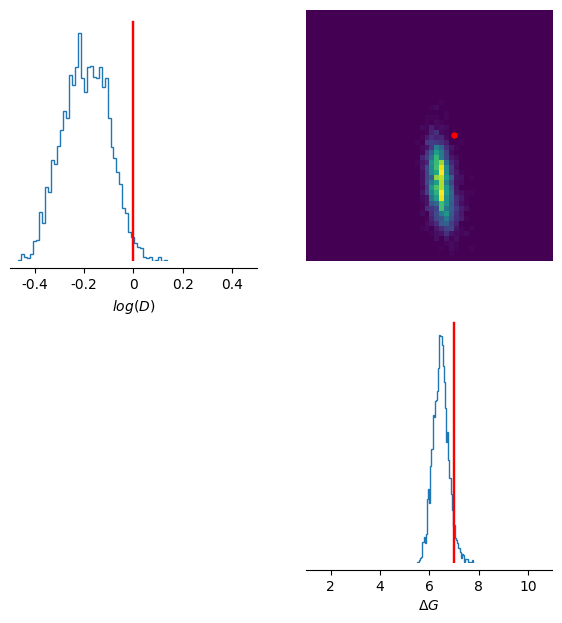

In [42]:
_ = analysis.pairplot(
    samples,
    limits=[prior_cfg['logD_lims'], prior_cfg['dG_lims']],
    figsize=(7,7),
    points=true_params, 
    points_offdiag={'markersize': 6},
    points_colors='r', 
    labels=['$log(D)$', '$\Delta G$']
)